# 01 — Exploring MovieLens `ml-latest-small`

Before building any model, I want to actually look at the data I'm going to
feed it. This notebook answers three questions I need answered before the rest
of the project makes sense:

1. How sparse is this dataset, and why does that matter for the model choice?
2. What real *context* signal is actually in here (vs. what I'll have to
   simulate)?
3. Where would cold-start actually bite?

Dataset: [MovieLens `ml-latest-small`](https://huggingface.co/datasets/johnidouglas/movie_lens_small_latest),
committed under `data/raw/ml-latest-small/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("..") / "data" / "raw" / "ml-latest-small"

ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
links = pd.read_csv(DATA_DIR / "links.csv")

ratings.shape, movies.shape, tags.shape, links.shape


Matplotlib is building the font cache; this may take a moment.


((100836, 4), (9742, 3), (3683, 4), (9742, 3))

## 1. Sparsity

A two-tower model has to learn a useful embedding for every user and every
item from whatever signal it has. The first thing worth knowing is just how
little signal that typically is.


In [2]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)
density = n_ratings / (n_users * n_movies)

print(f"users:          {n_users}")
print(f"movies rated:   {n_movies}")
print(f"ratings:        {n_ratings}")
print(f"density:        {density:.4%}  (the user-item matrix is {1 - density:.2%} empty)")


users:          610
movies rated:   9724
ratings:        100836
density:        1.7000%  (the user-item matrix is 98.30% empty)


That density number is the whole reason collaborative filtering (matrix
factorization) works at all for sparse data — it doesn't need every cell
filled in, it needs enough overlapping patterns to factorize. But it's also
why *adding* signal (context, metadata, text) has somewhere to help: the raw
interaction matrix alone is mostly blank.


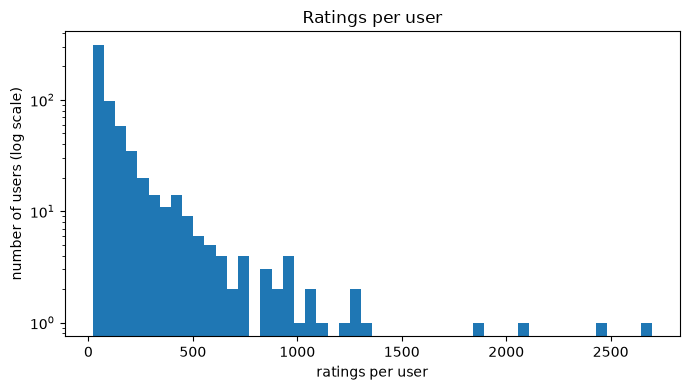

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

In [3]:
ratings_per_user = ratings.groupby("userId").size()

fig, ax = plt.subplots(figsize=(7, 4))
ratings_per_user.plot(kind="hist", bins=50, ax=ax, log=True)
ax.set_xlabel("ratings per user")
ax.set_ylabel("number of users (log scale)")
ax.set_title("Ratings per user")
plt.tight_layout()
plt.show()

ratings_per_user.describe()


**Note on cold-start in this specific dataset:** `ml-latest-small` only
includes users with at least 20 ratings — GroupLens filtered out the true
cold-start users before publishing it. So there's no *naturally occurring*
cold-start case to evaluate against here. In notebook 4, I simulate it
deliberately: hide a user's ID at training time for a slice of rows, and at
evaluation time, score some users using only their most recent ratings (the
"user-take" feature) with no learned user embedding at all — mimicking what a
brand-new signed-up user would look like.


## 2. What context signal actually exists here

The article that inspired this project's feature set uses device, time of
day, and day of week as request-time context. MovieLens has **no device
field** — so "device" will be a simulated UI toggle later, not a real learned
signal, and I'm calling that out now so it doesn't look like I'm hiding it.
Day of week and time of day, though, are real: every rating has a Unix
timestamp.


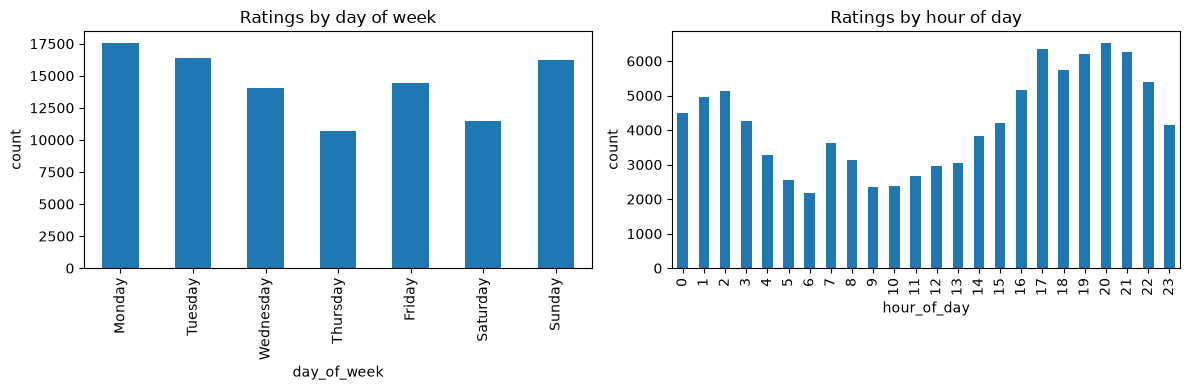

In [4]:
ts = pd.to_datetime(ratings["timestamp"], unit="s")
ratings["day_of_week"] = ts.dt.day_name()
ratings["hour_of_day"] = ts.dt.hour

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ratings["day_of_week"].value_counts().reindex(day_order).plot(kind="bar", ax=axes[0])
axes[0].set_title("Ratings by day of week")
axes[0].set_ylabel("count")

ratings["hour_of_day"].value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Ratings by hour of day")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()


Whether this is "real" context in the sense the article means — a genuine
in-the-moment viewing context — is a fair question. Rating timestamps on
MovieLens are when someone *rated* a movie, not necessarily when they watched
it, and plenty of ratings get entered in a batch, long after viewing. I'm
treating day-of-week/hour-of-day as a real, if noisy, proxy for request-time
context — good enough to prove the mechanism (does the model's output change
when context changes?), not good enough to claim it captures Joyn-grade signal
quality. Worth being honest about in the final write-up.


## 3. Item text: genres, titles, and tags

For the item-tower text embeddings, I need real text. `movies.csv` has
titles and genres; `tags.csv` has free-text tags users actually typed.


In [5]:
print(movies.head(3).to_string())
print()
print("sample tags:")
print(tags["tag"].sample(10, random_state=0).tolist())


   movieId                    title                                       genres
0        1         Toy Story (1995)  Adventure|Animation|Children|Comedy|Fantasy
1        2           Jumanji (1995)                   Adventure|Children|Fantasy
2        3  Grumpier Old Men (1995)                               Comedy|Romance

sample tags:
['insomnia', 'Highly quotable', 'biopic', 'bad script', 'murder', 'high school', 'E.M. Forster', 'cerebral', 'remix culture', 'emotional']


In [6]:
movies_with_tags = tags["movieId"].nunique()
print(f"movies with at least one tag: {movies_with_tags} / {len(movies)} "
      f"({movies_with_tags / len(movies):.1%})")


movies with at least one tag: 1572 / 9742 (16.1%)


Most movies have **no** user-submitted tag — tags are a sparse, bonus signal,
not a reliable primary source. So in notebook 3, the text fed to the
sentence-transformer per movie will be: tags if any exist, concatenated;
otherwise fall back to title + genres. That fallback matters enough to call
out explicitly rather than let embeddings silently go missing for most of the
catalog.


## 4. Genre distribution

Just to see what's actually in the catalog.


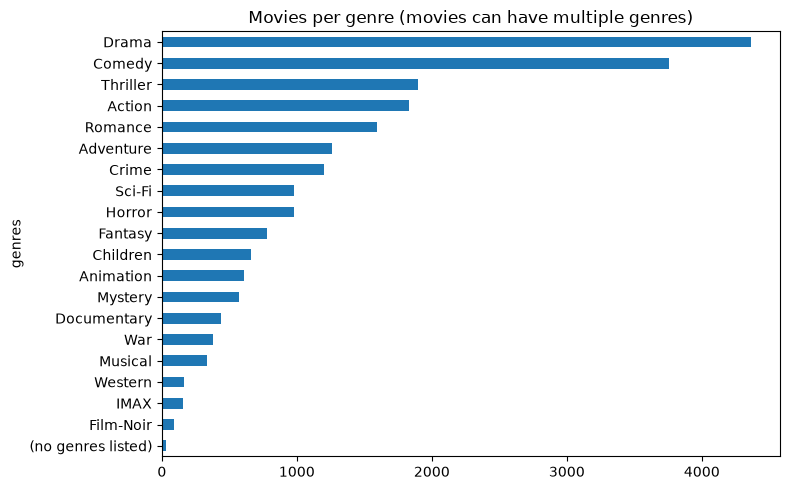

In [7]:
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

fig, ax = plt.subplots(figsize=(8, 5))
genre_counts.plot(kind="barh", ax=ax)
ax.set_title("Movies per genre (movies can have multiple genres)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


## My take — ADR-001

> Two-tower vs. matrix factorization — at what point does context/metadata/
> cold-start actually justify the added complexity, for *this* dataset's
> scale (~610 users, ~9,700 movies, ~100K ratings)?

Write the answer in `docs/ARCHITECTURE_DECISIONS.md` (ADR-001) once you've
seen the actual numbers in notebook 4 — not before. A reasonable prior from
*this* notebook alone: at ~610 users, the dataset is almost certainly too
small and too static for context/cold-start handling to show a dramatic win in
aggregate metrics — but it's exactly the kind of win that matters
disproportionately for user experience (new users, moment-to-moment
relevance) even when it barely moves an averaged Recall@K. That tension is
worth writing down once there's a real ablation number to react to.
